# Density estimation with a Dirichlet process Gaussian mixture

This notebook illustrates the `dpgmm` crate through its Python bindings.

A DP-GMM describes data as a mixture of Gaussians **without fixing the number of components**: the number is inferred together with the means and covariances by Gibbs sampling. `dpgmm.fit` returns the mixture of the last Gibbs sweep, which is *one draw from the posterior over mixtures*, not an average.

Contents:

1. One-dimensional examples
2. A fit is a posterior draw: variability across seeds
3. Effect of the number of observations
4. Effect of the number of Gibbs sweeps
5. Two-dimensional examples
6. Runtime
7. How LF-NS uses the estimate: the proposal region

To run it: `uv sync` in the repository root (this compiles the Rust code in release mode), then `uv run jupyter lab`. After changing Rust code, rebuild with `uv sync --reinstall-package dpgmm`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
from scipy import stats

import dpgmm

import notebook_style as style

style.apply()
# Colours by role: observations are neutral, the truth is ink, the fit is blue, its components orange.
INK, MUTED = style.INK, style.MUTED
OBSERVATIONS, FIT, COMPONENTS, FIT_RAMP = style.NEUTRAL, style.BLUE, style.ORANGE, style.BLUE_RAMP

## 1. One-dimensional examples

Four targets with different difficulties for a mixture of Gaussians:

- a **single Gaussian**: the simplest case;
- a **bimodal** mixture with unequal weights and widths;
- a **skewed** (log-normal) density, which no single Gaussian matches;
- a **uniform** density with hard edges. This is the shape of the constrained prior in nested sampling with a *deterministic* likelihood.

In [2]:
def draw_bimodal(rng, n):
    from_first = rng.random(n) < 0.6
    return np.where(from_first, rng.normal(-2.0, 0.5, n), rng.normal(3.0, 1.5, n))

def bimodal_pdf(x):
    return 0.6 * stats.norm.pdf(x, -2.0, 0.5) + 0.4 * stats.norm.pdf(x, 3.0, 1.5)

TARGETS_1D = {
    "Single Gaussian": (lambda rng, n: rng.normal(0.0, 1.0, n), lambda x: stats.norm.pdf(x)),
    "Bimodal": (draw_bimodal, bimodal_pdf),
    "Skewed (log-normal)": (lambda rng, n: rng.lognormal(0.0, 0.6, n), lambda x: stats.lognorm.pdf(x, 0.6)),
    "Uniform": (lambda rng, n: rng.random(n), lambda x: stats.uniform.pdf(x)),
}

def density_on_grid(mixture, grid):
    return np.exp(mixture.log_density(grid[:, None]))

def component_densities(mixture, grid):
    stds = np.sqrt(mixture.covariances[:, 0, 0])
    return [w * stats.norm.pdf(grid, m, s) for w, m, s in zip(mixture.weights, mixture.means[:, 0], stds)]

def plot_fit_1d(ax, sample, true_pdf, mixture, title, show_components=True):
    margin = 0.25 * (sample.max() - sample.min())
    grid = np.linspace(sample.min() - margin, sample.max() + margin, 600)
    ax.hist(sample, bins=40, density=True, color=OBSERVATIONS, alpha=0.45, label="observations")
    if show_components:
        for index, density in enumerate(component_densities(mixture, grid)):
            ax.plot(grid, density, color=COMPONENTS, lw=1.0, label="components" if index == 0 else None)
    ax.plot(grid, true_pdf(grid), color=INK, lw=1.5, ls="--", label="true density")
    ax.plot(grid, density_on_grid(mixture, grid), color=FIT, label="DP-GMM fit")
    ax.set_title(f"{title}: {mixture.n_components} component(s)")
    ax.set_yticks([])

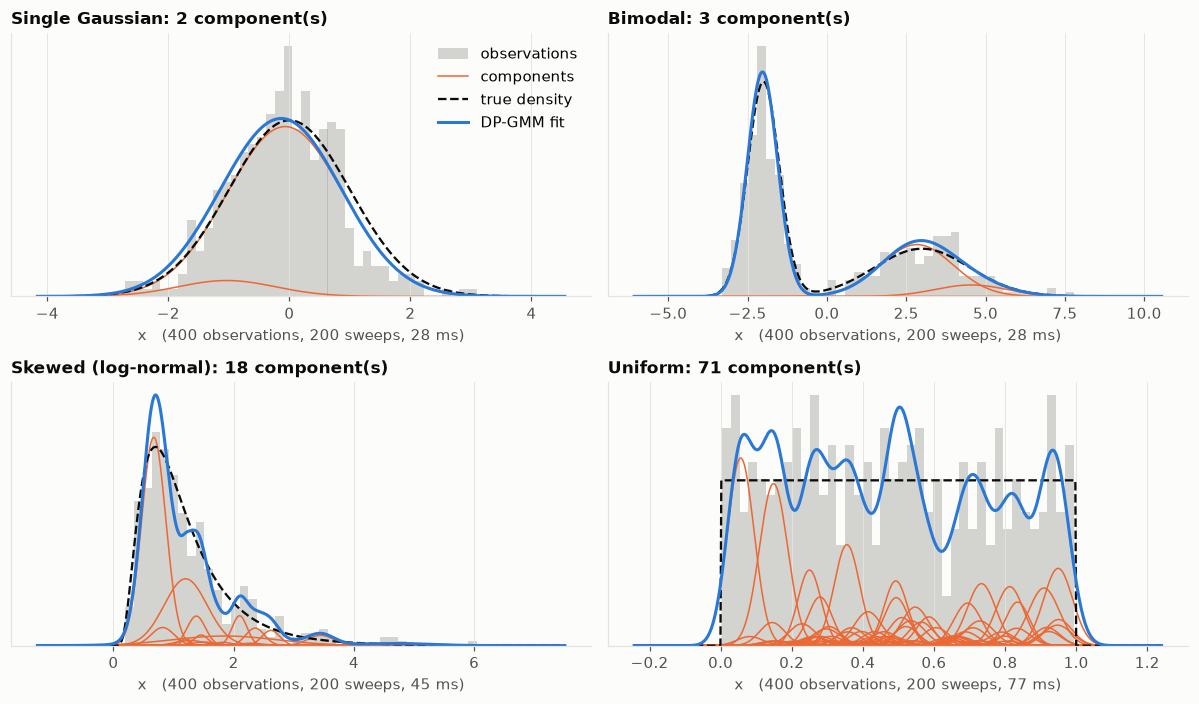

In [3]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (name, (draw, pdf)) in zip(axes.ravel(), TARGETS_1D.items()):
    sample = draw(rng, 400)
    start = time.perf_counter()
    mixture = dpgmm.fit(sample[:, None], seed=0)
    elapsed_ms = 1e3 * (time.perf_counter() - start)
    plot_fit_1d(ax, sample, pdf, mixture, name)
    ax.set_xlabel(f"x   (400 observations, 200 sweeps, {elapsed_ms:.0f} ms)")
axes[0, 0].legend(loc="upper right")
fig.tight_layout()

Things to notice:

- For the Gaussian-shaped targets the fit uses very few components: two for the single Gaussian (one of them small) and three for the bimodal target.
- The skewed density is approximated by chaining Gaussians of different widths.
- The uniform density is the hard case. No small set of Gaussians is flat, so the sampler breaks it into dozens of narrow components and the fit follows the sampling noise of the observations. It also cannot match the hard edges: Gaussians leak mass beyond them, which LF-NS handles by rejecting proposals outside the prior bounds.
- The number of components is not a count of clusters. A Dirichlet process keeps small, overlapping components alive, and they come and go between sweeps. Read the blue curve, not the count.

## 2. A fit is a posterior draw: variability across seeds

The same observations are fitted 20 times with different seeds. The spread of the curves shows how much a single draw can differ from another. It is small where data are plentiful and larger in the tails.

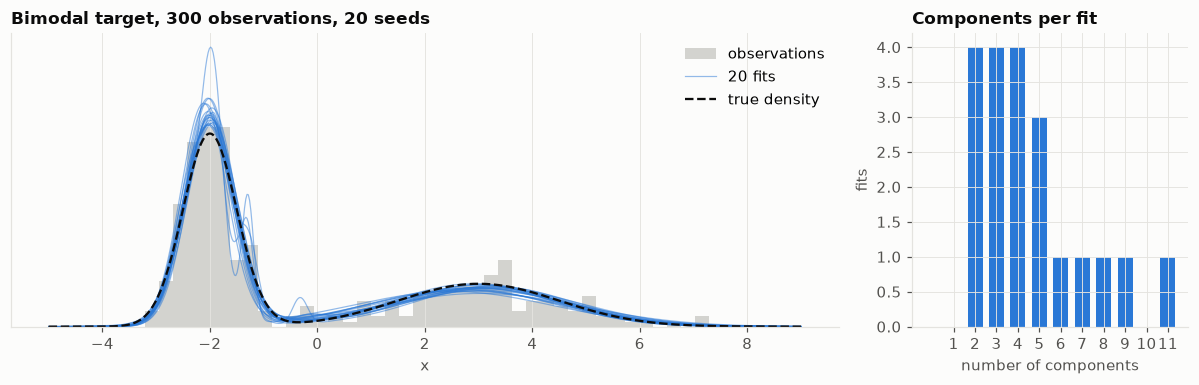

In [4]:
rng = np.random.default_rng(2)
sample = draw_bimodal(rng, 300)
grid = np.linspace(-5.0, 9.0, 600)
fits = [dpgmm.fit(sample[:, None], seed=seed) for seed in range(20)]

fig, (ax, ax_counts) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1]})
ax.hist(sample, bins=40, density=True, color=OBSERVATIONS, alpha=0.45, label="observations")
for index, mixture in enumerate(fits):
    ax.plot(grid, density_on_grid(mixture, grid), color=FIT, lw=0.8, alpha=0.5, label="20 fits" if index == 0 else None)
ax.plot(grid, bimodal_pdf(grid), color=INK, lw=1.5, ls="--", label="true density")
ax.set_title("Bimodal target, 300 observations, 20 seeds")
ax.set_yticks([]); ax.set_xlabel("x"); ax.legend()

counts = np.bincount([mixture.n_components for mixture in fits])
ax_counts.bar(np.arange(len(counts)), counts, color=FIT, width=0.7)
ax_counts.set_title("Components per fit"); ax_counts.set_xlabel("number of components"); ax_counts.set_ylabel("fits")
ax_counts.set_xticks(np.arange(1, len(counts)))
fig.tight_layout()

## 3. Effect of the number of observations

In LF-NS the mixture is fitted to the live particles that survive an iteration, typically a few hundred to a few thousand points. With few observations the prior dominates and the fit is broad; with more it sharpens.

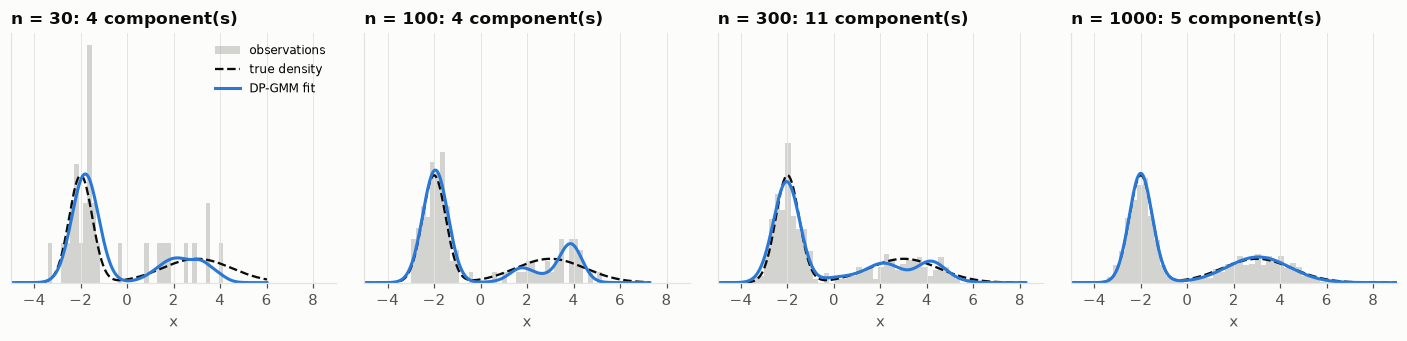

In [5]:
rng = np.random.default_rng(3)
sizes = [30, 100, 300, 1000]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, n in zip(axes, sizes):
    sample = draw_bimodal(rng, n)
    mixture = dpgmm.fit(sample[:, None], seed=0)
    plot_fit_1d(ax, sample, bimodal_pdf, mixture, f"n = {n}", show_components=False)
    ax.set_xlim(-5, 9); ax.set_xlabel("x")
axes[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()

## 4. Effect of the number of Gibbs sweeps

The sampler starts with all points unassigned and a central guess for the hyperparameters. Because the random stream is the same, a fit with `n_sweeps = k` and a given seed is exactly the state of that seed's chain after `k` sweeps. This lets us follow chains over time.

Quality is measured on 5,000 held-out points as the average of `log p_true(x) - log p_fit(x)`, an estimate of the Kullback-Leibler divergence from the truth (0 is perfect).

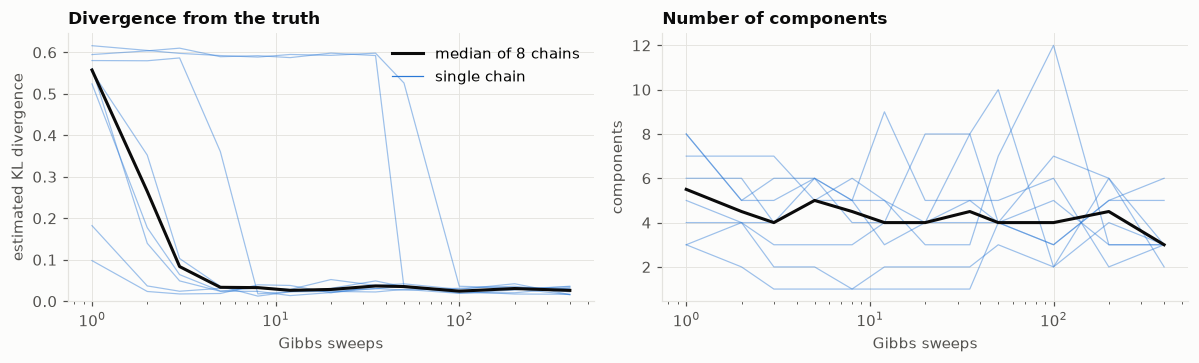

In [6]:
rng = np.random.default_rng(4)
sample = draw_bimodal(rng, 300)
held_out = draw_bimodal(rng, 5000)
sweep_counts = [1, 2, 3, 5, 8, 12, 20, 35, 50, 100, 200, 400]
seeds = range(8)

divergence = np.empty((len(seeds), len(sweep_counts)))
n_components = np.empty_like(divergence)
for i, seed in enumerate(seeds):
    for j, n_sweeps in enumerate(sweep_counts):
        mixture = dpgmm.fit(sample[:, None], n_sweeps=n_sweeps, seed=seed)
        divergence[i, j] = np.mean(np.log(bimodal_pdf(held_out)) - mixture.log_density(held_out[:, None]))
        n_components[i, j] = mixture.n_components

fig, (ax_kl, ax_k) = plt.subplots(1, 2, figsize=(11, 3.4))
for values, ax, title, label in [(divergence, ax_kl, "Divergence from the truth", "estimated KL divergence"),
                                 (n_components, ax_k, "Number of components", "components")]:
    ax.plot(sweep_counts, values.T, color=FIT, lw=0.8, alpha=0.45)
    ax.plot(sweep_counts, np.median(values, axis=0), color=INK, lw=2.0, label="median of 8 chains")
    ax.set_xscale("log"); ax.set_xlabel("Gibbs sweeps"); ax.set_ylabel(label); ax.set_title(title)
ax_kl.plot([], [], color=FIT, lw=0.8, label="single chain"); ax_kl.legend()
ax_kl.set_ylim(bottom=0)
fig.tight_layout()

Most chains reach a good fit within about five sweeps, after which the curves fluctuate without trend, as successive posterior draws do.

**Some chains start badly and need time.** Three of the eight chains begin with one broad component covering both modes and stay there for 35 to 50 sweeps (the flat lines near 0.6) before the component finally splits. The sampler moves one point at a time, and splitting a large component that way is slow. By 100 sweeps every chain has recovered, which is why the default is 200 sweeps. A fit that is still stuck would be valid for LF-NS but wasteful: its proposal region is too large, so the acceptance rate of that iteration drops.

## 5. Two-dimensional examples

Blue contours show the fitted log-density (darker is denser), orange ellipses the one-standard-deviation outline of each component with at least 2% weight.

- **Two clusters** of different size and shape.
- **Banana**: a curved ridge, typical of correlated, weakly identified parameters.
- **Ring**: a density with a hole, which needs many components.
- **Uniform disc**: a flat density with a hard edge.

In [7]:
def draw_two_clusters(rng, n):
    broad = rng.multivariate_normal([0.0, 0.0], [[1.0, 0.8], [0.8, 1.0]], n)
    narrow = rng.multivariate_normal([4.0, -2.5], [[0.15, 0.0], [0.0, 0.05]], n)
    return np.where((rng.random(n) < 0.7)[:, None], broad, narrow)

def draw_banana(rng, n):
    x = rng.normal(0.0, 1.0, n)
    return np.column_stack([x, x**2 + rng.normal(0.0, 0.3, n)])

def draw_ring(rng, n):
    angle, radius = rng.uniform(0.0, 2.0 * np.pi, n), rng.normal(3.0, 0.25, n)
    return np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])

def draw_disc(rng, n):
    angle, radius = rng.uniform(0.0, 2.0 * np.pi, n), np.sqrt(rng.random(n))
    return np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])

TARGETS_2D = {"Two clusters": draw_two_clusters, "Banana": draw_banana, "Ring": draw_ring, "Uniform disc": draw_disc}

def grid_2d(points, resolution=160, margin=0.2):
    low, high = points.min(axis=0), points.max(axis=0)
    pad = margin * (high - low)
    xs = np.linspace(low[0] - pad[0], high[0] + pad[0], resolution)
    ys = np.linspace(low[1] - pad[1], high[1] + pad[1], resolution)
    mesh_x, mesh_y = np.meshgrid(xs, ys)
    return mesh_x, mesh_y, np.column_stack([mesh_x.ravel(), mesh_y.ravel()])

def draw_component_ellipses(ax, mixture, min_weight=0.02):
    for weight, mean, covariance in zip(mixture.weights, mixture.means, mixture.covariances):
        if weight < min_weight:
            continue
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        angle = np.degrees(np.arctan2(eigenvectors[1, 1], eigenvectors[0, 1]))
        width, height = 2.0 * np.sqrt(eigenvalues[1]), 2.0 * np.sqrt(eigenvalues[0])
        ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, edgecolor=COMPONENTS, lw=1.5))

def plot_fit_2d(ax, points, mixture, title):
    mesh_x, mesh_y, grid = grid_2d(points)
    log_density = mixture.log_density(grid).reshape(mesh_x.shape)
    levels = log_density.max() - np.array([8.0, 6.0, 4.0, 2.5, 1.2])  # ascending: outermost first
    ax.scatter(points[:, 0], points[:, 1], s=5, color=OBSERVATIONS, alpha=0.6, linewidths=0)
    ax.contour(mesh_x, mesh_y, log_density, levels=levels, colors=FIT_RAMP, linewidths=1.4)
    draw_component_ellipses(ax, mixture)
    ax.set_title(title); ax.set_aspect("equal", adjustable="datalim"); ax.grid(False)

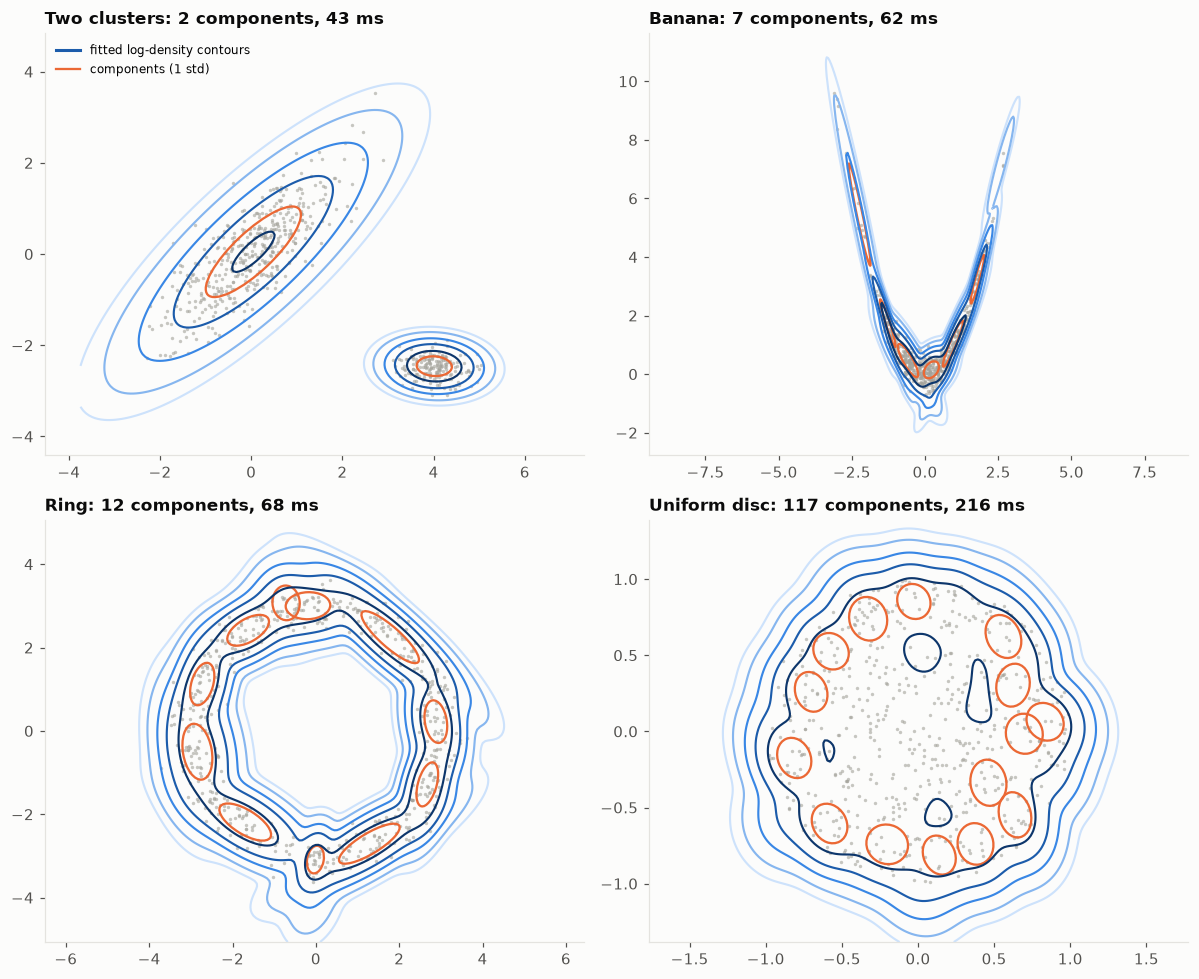

In [8]:
rng = np.random.default_rng(5)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, draw) in zip(axes.ravel(), TARGETS_2D.items()):
    points = draw(rng, 600)
    start = time.perf_counter()
    mixture = dpgmm.fit(points, seed=0)
    elapsed_ms = 1e3 * (time.perf_counter() - start)
    plot_fit_2d(ax, points, mixture, f"{name}: {mixture.n_components} components, {elapsed_ms:.0f} ms")
axes[0, 0].plot([], [], color=FIT_RAMP[3], label="fitted log-density contours")
axes[0, 0].plot([], [], color=COMPONENTS, lw=1.5, label="components (1 std)")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.tight_layout()

The banana and the ring show the strength of the approach compared with a single ellipsoid: the mixture follows curved and hollow shapes by chaining components. An ellipsoid around the ring would be mostly empty.

## 6. Runtime

All timings are single-threaded, release build, median of three fits with the default 200 sweeps. One sweep visits every point once and evaluates its predictive density under every component, so the cost grows with the number of points, the number of components, and the square of the dimension (plus a cubic term for refactorizing a component when a point moves).

observations  ms    components
         100  7     2
         200  14    2
         500  37    2
        1000  68    2
        2000  141   3
        5000  359   5

dimension  ms    components
        1  88    17
        2  96    4
        5  118   1
       10  224   2
       20  709   1


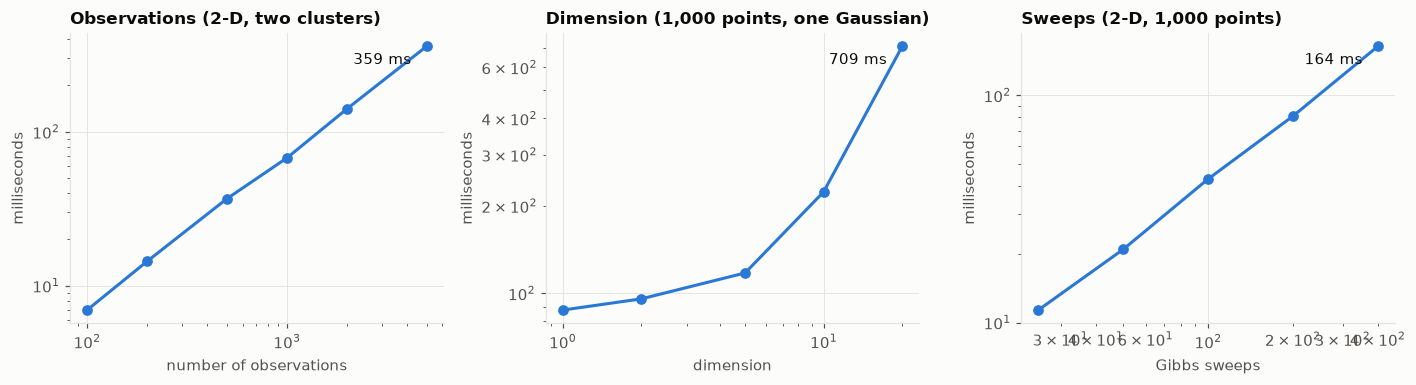

In [9]:
def median_fit_seconds(points, n_sweeps=200, repeats=3):
    timings = []
    for seed in range(repeats):
        start = time.perf_counter()
        mixture = dpgmm.fit(points, n_sweeps=n_sweeps, seed=seed)
        timings.append(time.perf_counter() - start)
    return np.median(timings), mixture.n_components

rng = np.random.default_rng(6)
point_counts = [100, 200, 500, 1000, 2000, 5000]
by_count = [median_fit_seconds(draw_two_clusters(rng, n)) for n in point_counts]
dimensions = [1, 2, 5, 10, 20]
by_dimension = [median_fit_seconds(rng.normal(size=(1000, d))) for d in dimensions]
sweep_options = [25, 50, 100, 200, 400]
by_sweeps = [median_fit_seconds(draw_two_clusters(rng, 1000), n_sweeps=s) for s in sweep_options]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [(point_counts, by_count, "Observations (2-D, two clusters)", "number of observations"),
          (dimensions, by_dimension, "Dimension (1,000 points, one Gaussian)", "dimension"),
          (sweep_options, by_sweeps, "Sweeps (2-D, 1,000 points)", "Gibbs sweeps")]
for ax, (xs, results, title, xlabel) in zip(axes, panels):
    seconds = [1e3 * result[0] for result in results]
    ax.plot(xs, seconds, color=FIT, marker="o", markersize=6)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("milliseconds")
    ax.annotate(f"{seconds[-1]:.0f} ms", (xs[-1], seconds[-1]), textcoords="offset points", xytext=(-10, -4), ha="right", va="top", color=INK)
fig.tight_layout()

print("observations  ms    components")
for n, (seconds, k) in zip(point_counts, by_count):
    print(f"{n:>12}  {1e3 * seconds:<5.0f} {k}")
print("\ndimension  ms    components")
for d, (seconds, k) in zip(dimensions, by_dimension):
    print(f"{d:>9}  {1e3 * seconds:<5.0f} {k}")

For the sizes LF-NS uses (hundreds to a few thousand live points, up to about twenty parameters) a fit takes from a few milliseconds to about a second. It is done once per iteration, so it is negligible next to the likelihood evaluations whenever those involve solving a differential equation.

## 7. How LF-NS uses the estimate: the proposal region

LF-NS does not sample from the mixture directly. It needs candidates that are **uniform** over a region containing all points that could still be accepted. That region is where the fitted density exceeds a floor, and the floor is a low quantile of the density of the mixture's own draws.

A draw `x` from the mixture is kept with probability `floor / density(x)` and dropped where the density is below the floor, which turns mixture draws into uniform draws over the region.

The quantile trades acceptance rate against coverage. Below, the same fit is shown with the default quantile of 0.1% and with 5%. The coverage is the fraction of fresh points from the true distribution that fall inside the region; anything missed biases the evidence upward.

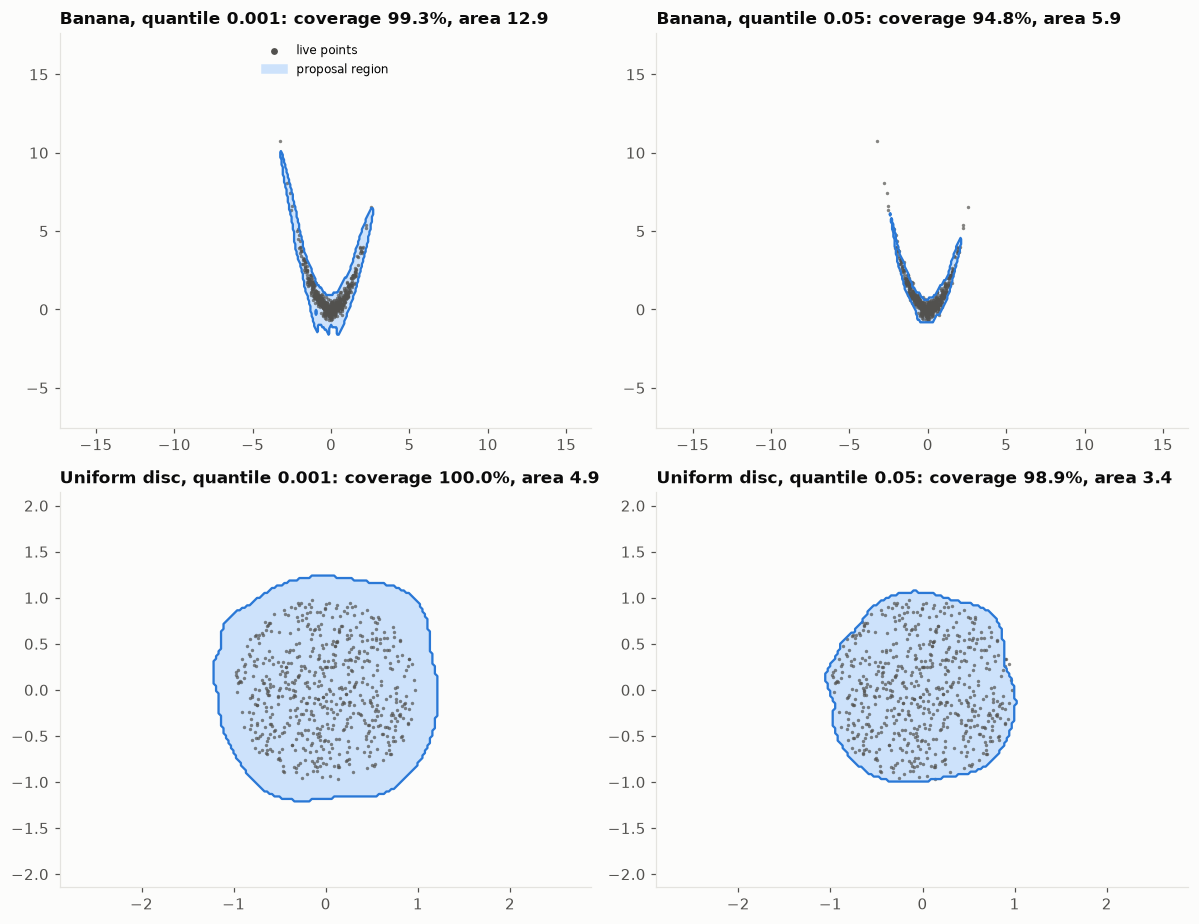

In [10]:
def density_floor(mixture, quantile, n_draws=1000, seed=0):
    # Same rule as the Rust proposal: a low quantile of the log-density of the mixture's own draws.
    return np.quantile(mixture.log_density(mixture.sample(n_draws, seed)), quantile)

rng = np.random.default_rng(7)
quantiles = [0.001, 0.05]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for row, (name, draw) in zip(axes, [("Banana", draw_banana), ("Uniform disc", draw_disc)]):
    points, fresh = draw(rng, 600), draw(rng, 20000)
    mixture = dpgmm.fit(points, seed=0)
    mesh_x, mesh_y, grid = grid_2d(points, margin=0.6)
    log_density = mixture.log_density(grid).reshape(mesh_x.shape)
    cell_area = (mesh_x[0, 1] - mesh_x[0, 0]) * (mesh_y[1, 0] - mesh_y[0, 0])
    for ax, quantile in zip(row, quantiles):
        floor = density_floor(mixture, quantile)
        inside = log_density >= floor
        coverage = np.mean(mixture.log_density(fresh) >= floor)
        ax.contourf(mesh_x, mesh_y, inside, levels=[0.5, 1.5], colors=[FIT_RAMP[0]])
        ax.contour(mesh_x, mesh_y, inside, levels=[0.5], colors=[FIT], linewidths=1.5)
        ax.scatter(points[:, 0], points[:, 1], s=5, color=MUTED, alpha=0.7, linewidths=0)
        ax.set_title(f"{name}, quantile {quantile:g}: coverage {100 * coverage:.1f}%, area {inside.sum() * cell_area:.1f}")
        ax.set_aspect("equal", adjustable="datalim"); ax.grid(False)
axes[0, 0].scatter([], [], s=12, color=MUTED, label="live points")
axes[0, 0].fill_between([], [], [], color=FIT_RAMP[0], label="proposal region")
axes[0, 0].legend(loc="upper center", fontsize=8)
fig.tight_layout()

With the default quantile the region is generous: it covers essentially all of the true distribution, at the cost of proposing in some empty space. Raising the quantile shrinks the region and raises the acceptance rate, but begins to cut into the true support. In the end-to-end tests of `lfns`, a quantile of 5% produced a measurable upward bias of the evidence (about +0.12 in `ln Z`), while 0.1% showed none.